# Block 4 Data Summary: Half-Hourly FLUXNET Observations Across Five Ecosystems
**Author:** Sanglap Roy (Student 22)  
**Data source & versions:** FLUXNET Shuttle snapshot `fluxnet_shuttle_snapshot_20261116T075027.csv`, ONEFlux processing `v1.3_r1` (`_FLUXMET_HH_` half-hourly archives in `data/raw/`, downloaded 16 November 2026).  
**Methods & variable choices:**
- Missing values (`-9999`) are read as `NaN` via `scripts/read_flux.py` (`read_hh()`).
- Timestamps (`TIMESTAMP_START`) are parsed from text to `datetime64` in **local standard time** (no daylight-saving jump).
- Carbon fluxes use the variable-u\*-threshold reference product (`_VUT_REF`) with **night-time partitioning** (`GPP_NT_VUT_REF`, `RECO_NT_VUT_REF`) and quality flag `NEE_VUT_REF_QC` (`0` = measured, `> 0` = gap-filled).
- Meteorology (`TA_F`, `SW_IN_F`, `VPD_F`, `P_F`) and energy fluxes (`NETRAD`, `G_F_MDS`, `H_F_MDS`, `LE_F_MDS`) use gap-filled (`_F` / `_F_MDS`) series, with `H_F_MDS_QC == 0` and `LE_F_MDS_QC == 0` selecting measured turbulent fluxes for energy-balance closure.

In [1]:
#| echo: false
#| warning: false
import os
import sys
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, HTML, Markdown
display(HTML("""<style>
.cell-output-display,
.cell-output-display figure,
.cell-output-display .figure,
.quarto-figure {
  display: block !important;
  width: 100% !important;
  max-width: 100% !important;
}
.cell-output-display img {
  display: block !important;
  max-width: 100% !important;
  height: auto !important;
  margin-inline: auto;
}
</style>"""))
# Ensure working directory is repository root whether run from root or reports/
ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists() and (ROOT.parent / "data" / "raw").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.read_flux import read_hh
FIG_DIR = Path("outputs/figurs") if Path("outputs/figurs").exists() else Path("outputs/figures")
TAB_DIR = Path("outputs/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
SITES = ["AU-How", "BE-Lon", "ID-PaD", "NL-Vkp", "US-Vcm"]
SITE_COLORS = {
    "AU-How": "#d95f02",
    "BE-Lon": "#1b9e77",
    "ID-PaD": "#7570b3",
    "NL-Vkp": "#e7298a",
    "US-Vcm": "#386cb0",
}
COUNTRY_MAP = {
    "AU": "Australia",
    "BE": "Belgium",
    "ID": "Indonesia",
    "NL": "Netherlands",
    "US": "USA",
}
snap_path = sorted(Path("data/snapshots").glob("fluxnet_shuttle_snapshot_*.csv"))[-1]
snap = pd.read_csv(snap_path)
snap["site_id"] = snap["site_id"].astype(str).str.strip()
meta = snap[snap["site_id"].isin(SITES)].drop_duplicates("site_id").copy()
meta["country"] = meta["site_id"].str[:2].map(COUNTRY_MAP)
meta = meta.sort_values("site_id").reset_index(drop=True)
zip_files = sorted(Path("data/raw").glob("*.zip"))
print("Snapshot file:", snap_path.name)
print("Archive files:", [z.name for z in zip_files])
df = pd.concat([read_hh(z) for z in zip_files], ignore_index=True)
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month
df["hour"] = df["time"].dt.hour + df["time"].dt.minute / 60.0
print(f"Loaded {len(df):,} half-hourly rows across {df['site'].nunique()} sites (duplicates: {df.duplicated(['site', 'time']).sum()}).")

Snapshot file: fluxnet_shuttle_snapshot_20261116T075027.csv
Archive files: ['AMF_US-Vcm_FLUXNET_2007-2025_v1.3_r1.zip', 'EUF_NL-Vkp_FLUXNET_2014-2025_v1.3_r1.zip', 'ICOS_BE-Lon_FLUXNET_2004-2024_v1.3_r1.zip', 'JPF_ID-PaD_FLUXNET_2001-2017_v1.3_r1.zip', 'TERN_AU-How_FLUXNET_2002-2025_v1.3_r1.zip']


Loaded 1,630,512 half-hourly rows across 5 sites (duplicates: 0).


## C1. Site Overview

Site ID,Name,Country,IGBP,Latitude (°),Longitude (°),First Year,Last Year,Hub,Data Citation
AU-How,Howard Springs,Australia,WSA,-12.4952,131.1500,2002,2025,TERN,"Beringer, J., Hutley, L., Northwood, M. (2026): Howard Springs FLUXNET Release 2026_r1 . Version 2026_r1. Terrestrial Ecosystem Research Network (TERN). (Dataset)."
BE-Lon,Lonzee,Belgium,CRO,50.5516,4.7462,2004,2024,ICOS,"Dumont, B., Heinesch, B., Bodson, B., Bogaerts, G., Chopin, H., De Ligne, A., Demoulin, L., Douxfils, B., Engelmann, T., Faurès, A., Longdoz, B., Manise, T., Orgun, A., Piret, A., Thyrion, T. (2026). Fluxnet Archive Product from Lonzee, 2004–2024, FLUXNET, https://hdl.handle.net/11676/1u2xQ5XcQoX0j2wJiZcyDP3M"
ID-PaD,Palangkaraya Drained forest,Indonesia,EBF,-2.3461,114.0364,2001,2017,ICOS,"Hirano, T., Ohkubo, S. (2026). Fluxnet Archive Product from Palangkaraya Drained forest, 2001–2017, FLUXNET, https://hdl.handle.net/11676/RaxQP0fkOSWCXKIIhi7Bnevj"
NL-Vkp,Veenkampen,Netherlands,GRA,51.9809,5.6188,2014,2025,ICOS,"Barten, J., Hartogensis, O., Heusinkveld, B. (2026). Fluxnet Archive Product from Veenkampen, 2014–2025, FLUXNET, https://hdl.handle.net/11676/NjPFe8mMhEmbG6xHDtKSw-sx"
US-Vcm,Valles Caldera Mixed Conifer,USA,ENF,35.8885,-106.5322,2007,2025,AmeriFlux,"Marcy Litvak (2026), AmeriFlux FLUXNET-1F US-Vcm Valles Caldera Mixed Conifer, Ver. v1.3_r1 (2007-2025), AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/2229391"


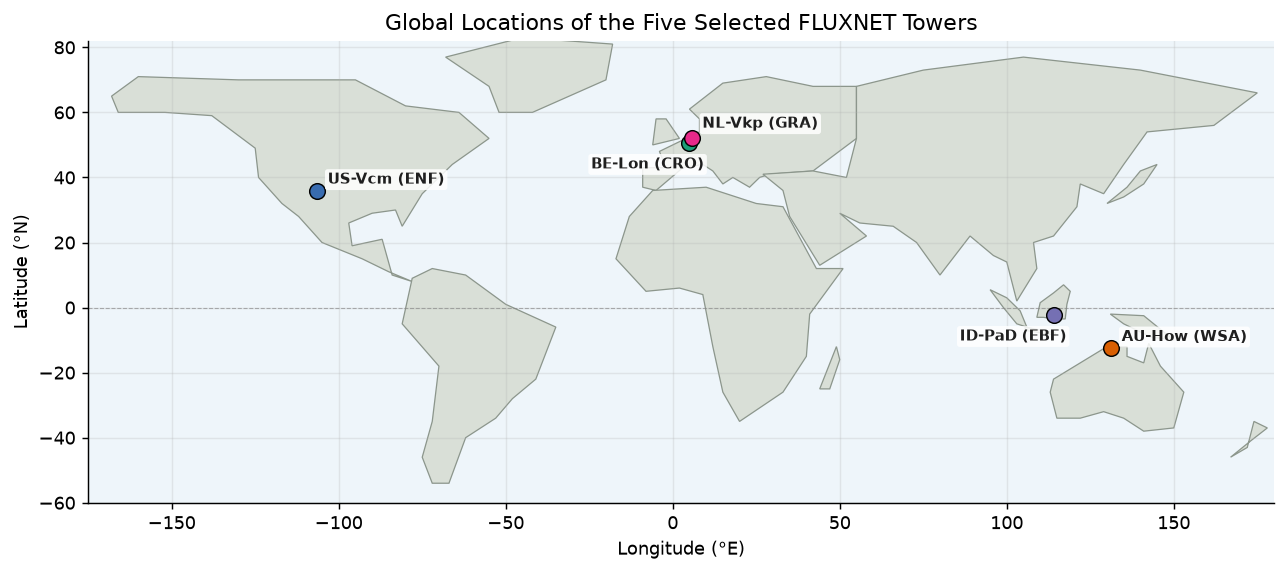

In [2]:
#| echo: false
#| warning: false
#| out-width: 100%
overview = meta[[
    "site_id", "site_name", "country", "igbp",
    "location_lat", "location_long", "first_year", "last_year",
    "data_hub", "product_citation"
]].rename(columns={
    "site_id": "Site ID",
    "site_name": "Name",
    "country": "Country",
    "igbp": "IGBP",
    "location_lat": "Latitude (°)",
    "location_long": "Longitude (°)",
    "first_year": "First Year",
    "last_year": "Last Year",
    "data_hub": "Hub",
    "product_citation": "Data Citation",
})
overview.to_csv(TAB_DIR / "c1_site_overview.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", None)
display(overview.style.hide(axis="index").format({
    "Latitude (°)": "{:.4f}",
    "Longitude (°)": "{:.4f}",
}))
# World map with simplified continent outlines (no external geospatial dependencies)
continents = [
    [(-168,65),(-160,71),(-130,70),(-95,70),(-80,62),(-64,60),(-55,52),(-66,44),(-75,35),
     (-81,25),(-83,30),(-90,29),(-97,26),(-96,19),(-87,21),(-84,10),(-78,8),(-85,11),
     (-93,15),(-105,20),(-112,28),(-117,32),(-124,40),(-125,49),(-138,59),(-152,60),(-166,60),(-168,65)],
    [(-52,60),(-42,60),(-20,70),(-18,81),(-45,83),(-68,77),(-55,68),(-52,60)],
    [(-78,9),(-72,12),(-62,10),(-50,1),(-35,-6),(-38,-14),(-41,-22),(-48,-28),
     (-53,-34),(-62,-40),(-67,-54),(-72,-54),(-75,-46),(-72,-35),(-70,-18),(-81,-5),(-78,9)],
    [(-9,37),(-9,43),(-2,43),(-4,48),(2,51),(8,54),(8,58),(5,61),(15,69),(28,71),(42,68),
     (55,68),(55,52),(42,42),(29,41),(26,40),(23,37),(18,40),(15,38),(12,42),(9,44),(3,43),(-5,36),(-9,37)],
    [(-6,50),(-5,58),(-2,58),(2,52),(-6,50)],
    [(-17,15),(-13,28),(-6,36),(10,37),(25,32),(33,31),(43,12),(51,12),(41,-2),
     (40,-15),(33,-26),(20,-35),(15,-26),(12,-12),(9,4),(2,6),(-8,5),(-17,15)],
    [(44,-25),(49,-12),(50,-16),(47,-25),(44,-25)],
    [(27,41),(42,42),(52,40),(55,52),(55,68),(75,73),(105,77),(140,73),(175,66),
     (162,56),(142,54),(135,44),(129,35),(122,38),(121,31),(114,22),(108,20),
     (109,12),(103,2),(100,14),(96,16),(89,22),(80,10),(73,20),(66,25),
     (56,26),(50,29),(58,22),(44,13),(35,28),(33,36),(27,41)],
    [(130,32),(135,34),(141,38),(145,44),(140,42),(136,37),(130,32)],
    [(95,5.5),(100,3),(104,-1),(106,-6),(103,-5),(99,0),(95,5.5)],
    [(109,-3),(110,1.5),(114,4.5),(117,7),(119,5),(118,1),(117.5,-3.5),(114,-3.5),(111,-3),(109,-3)],
    [(105.5,-6),(114.5,-7.8),(114.5,-8.5),(105.5,-7),(105.5,-6)],
    [(131,-2),(141,-2.5),(150,-10),(143,-9),(135,-5),(131,-2)],
    [(114,-22),(122,-17),(130,-12),(136,-12),(136,-15),(141,-17),(142.5,-11),(146,-18),
     (153,-26),(150,-37),(141,-38),(135,-34),(129,-32),(122,-34),(115,-34),(113,-26),(114,-22)],
    [(167,-46),(173,-41),(178,-37),(174,-35),(172,-43),(167,-46)],
]
fig, ax = plt.subplots(figsize=(10.0, 4.5))
ax.set_facecolor("#eef5fa")
for poly in continents:
    xs, ys = zip(*poly)
    ax.fill(xs, ys, facecolor="#d9dfd7", edgecolor="#8c968c", linewidth=0.7, zorder=1)
offsets = {
    "AU-How": (6, 4),
    "BE-Lon": (-54, -14),
    "ID-PaD": (-52, -14),
    "NL-Vkp": (6, 6),
    "US-Vcm": (6, 4),
}
for _, row in meta.iterrows():
    sid = row["site_id"]
    lon, lat = row["location_long"], row["location_lat"]
    ax.scatter(lon, lat, s=75, color=SITE_COLORS[sid], edgecolor="black", linewidth=0.8, zorder=3)
    dx, dy = offsets.get(sid, (5, 5))
    ax.annotate(f"{sid} ({row['igbp']})", (lon, lat), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5, fontweight="bold",
                color="#1f1f1f", bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.85), zorder=4)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.6, alpha=0.6)
ax.set_xlim(-175, 180)
ax.set_ylim(-60, 82)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Global Locations of the Five Selected FLUXNET Towers")
plt.tight_layout()
fig.savefig(FIG_DIR / "c1_site_locations_map.png", dpi=200, bbox_inches="tight")
plt.show()

## C2. Data Coverage

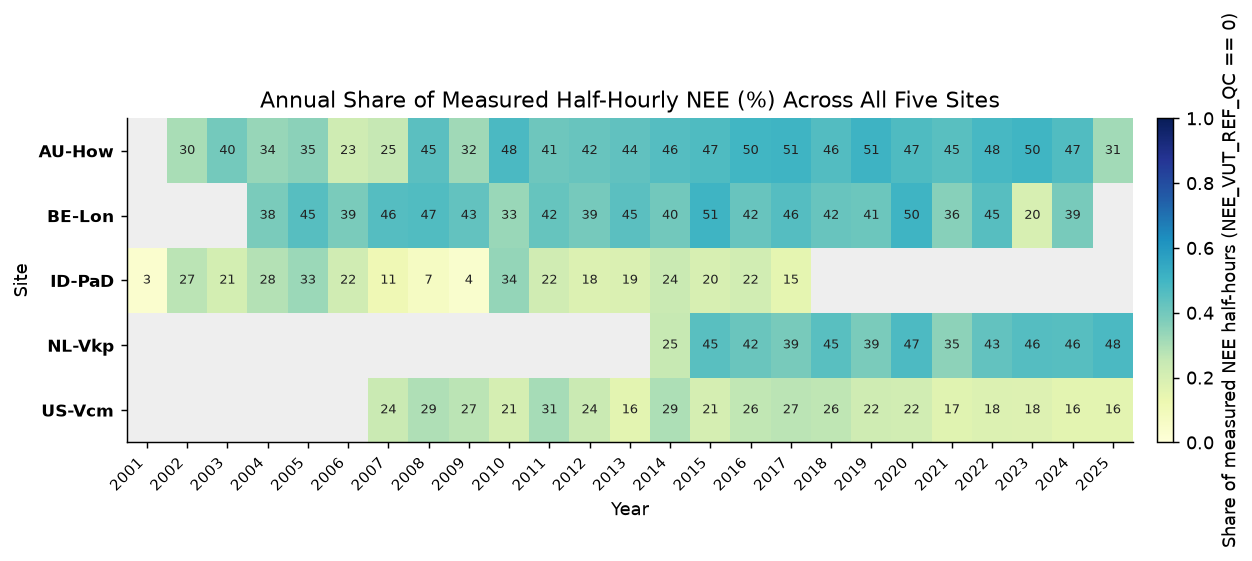

Best overall site: NL-Vkp (41.6% mean); highest single year: AU-How 2019 (50.9%).


In [3]:
#| echo: false
#| warning: false
#| out-width: 100%
cov = (
    df.groupby(["site", "year"])["NEE_VUT_REF_QC"]
    .apply(lambda s: (s == 0).mean())
    .unstack("year")
    .reindex(SITES)
)
cov.round(4).to_csv(TAB_DIR / "c2_nee_coverage_by_year.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(10.5, 3.6))
cmap = plt.cm.YlGnBu.copy()
cmap.set_bad(color="#eeeeee")
im = ax.imshow(cov.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=1)
years = cov.columns.to_list()
ax.set_xticks(np.arange(len(years)))
ax.set_xticklabels(years, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(np.arange(len(cov.index)))
ax.set_yticklabels(cov.index, fontsize=9.5, fontweight="bold")
ax.grid(False)
for i in range(len(cov.index)):
    for j in range(len(years)):
        val = cov.iloc[i, j]
        if pd.notna(val):
            txt_color = "white" if val > 0.55 else "#222222"
            ax.text(j, i, f"{val*100:.0f}", ha="center", va="center", fontsize=7, color=txt_color)
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Share of measured NEE half-hours (NEE_VUT_REF_QC == 0)")
ax.set_xlabel("Year")
ax.set_ylabel("Site")
ax.set_title("Annual Share of Measured Half-Hourly NEE (%) Across All Five Sites")
plt.tight_layout()
fig.savefig(FIG_DIR / "c2_nee_data_coverage.png", dpi=200, bbox_inches="tight")
plt.show()
best_site = cov.mean(axis=1).idxmax()
best_mean = cov.mean(axis=1).max() * 100
best_sy = cov.stack().idxmax()
best_sy_val = cov.stack().max() * 100
print(f"Best overall site: {best_site} ({best_mean:.1f}% mean); highest single year: {best_sy[0]} {best_sy[1]} ({best_sy_val:.1f}%).")

**Coverage note:** **AU-How**, **NL-Vkp**, and **BE-Lon** have the best overall measured NEE coverage (~`41.5%`–`41.6%` of all half-hours), with the single highest-coverage years occurring at **AU-How in 2019 (`50.9%`)**, **BE-Lon in 2015 (`50.6%`) and 2020 (`50.4%`)**, and **AU-How in 2017 (`50.5%`) and 2023 (`50.1%`)**; **ID-PaD** has the lowest overall measured NEE share (`19.4%`, with `15.1%` completely missing and <`7%` measured in `2001`, `2008`, and `2009`).
## C3. Summary Statistics

In [4]:
#| echo: false
#| warning: false
vars_info = [
    ("TA_F", "Air temperature", "°C"),
    ("SW_IN_F", "Incoming shortwave radiation", "W m⁻²"),
    ("VPD_F", "Vapour pressure deficit", "hPa"),
    ("P_F", "Precipitation (mean = annual sum)", "mm yr⁻¹ | mm (30 min)⁻¹"),
    ("NEE_VUT_REF", "Net ecosystem exchange", "µmol CO₂ m⁻² s⁻¹"),
    ("GPP_NT_VUT_REF", "Gross primary production (NT)", "µmol CO₂ m⁻² s⁻¹"),
    ("RECO_NT_VUT_REF", "Ecosystem respiration (NT)", "µmol CO₂ m⁻² s⁻¹"),
    ("H_F_MDS", "Sensible heat flux", "W m⁻²"),
    ("LE_F_MDS", "Latent heat flux", "W m⁻²"),
]
all_c3 = []
for site in SITES:
    sub = df[df["site"] == site]
    rows = []
    for col, label, unit in vars_info:
        s = sub[col]
        pct_miss = s.isna().mean() * 100
        if s.notna().sum() == 0:
            mean_str, min_str, max_str = "—", "—", "—"
        elif col == "P_F":
            mean_val = sub.groupby("year")["P_F"].sum().mean()
            mean_str = f"{mean_val:.1f} (mm yr⁻¹)"
            min_str = f"{s.min():.2f}"
            max_str = f"{s.max():.2f}"
        else:
            mean_str = f"{s.mean():.2f}"
            min_str = f"{s.min():.2f}"
            max_str = f"{s.max():.2f}"
        rows.append({
            "Variable (units)": f"{col} ({unit})",
            "Description": label,
            "Mean / Mean Annual Sum (P_F)": mean_str,
            "Minimum": min_str,
            "Maximum": max_str,
            "% Missing": f"{pct_miss:.2f}%",
        })
    tbl = pd.DataFrame(rows)
    sname = meta.loc[meta["site_id"] == site, "site_name"].iloc[0]
    igbp = meta.loc[meta["site_id"] == site, "igbp"].iloc[0]
    display(Markdown(f"### {site} — {sname} ({igbp})"))
    tbl.to_csv(TAB_DIR / f"c3_summary_stats_{site}.csv", index=False, encoding="utf-8-sig")
    all_c3.append(tbl.assign(Site=site)[["Site"] + list(tbl.columns)])
    display(tbl.style.hide(axis="index"))
pd.concat(all_c3, ignore_index=True).to_csv(TAB_DIR / "c3_summary_stats_all_sites.csv", index=False, encoding="utf-8-sig")


### AU-How — Howard Springs (WSA)

Variable (units),Description,Mean / Mean Annual Sum (P_F),Minimum,Maximum,% Missing
TA_F (°C),Air temperature,26.90,9.48,39.94,0.00%
SW_IN_F (W m⁻²),Incoming shortwave radiation,234.81,0.00,1287.00,0.00%
VPD_F (hPa),Vapour pressure deficit,12.66,0.00,57.79,0.00%
P_F (mm yr⁻¹ | mm (30 min)⁻¹),Precipitation (mean = annual sum),1672.3 (mm yr⁻¹),0.00,48.20,0.00%
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),Net ecosystem exchange,-1.92,-78.44,51.89,3.36%
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Gross primary production (NT),5.41,-45.86,81.38,11.68%
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Ecosystem respiration (NT),3.46,0.00,11.10,7.52%
H_F_MDS (W m⁻²),Sensible heat flux,42.12,-100.00,689.00,3.35%
LE_F_MDS (W m⁻²),Latent heat flux,87.99,-98.00,1076.00,3.35%


### BE-Lon — Lonzee (CRO)

Variable (units),Description,Mean / Mean Annual Sum (P_F),Minimum,Maximum,% Missing
TA_F (°C),Air temperature,11.15,-18.40,39.82,0.00%
SW_IN_F (W m⁻²),Incoming shortwave radiation,127.11,0.00,1045.30,0.00%
VPD_F (hPa),Vapour pressure deficit,3.27,0.00,59.38,0.00%
P_F (mm yr⁻¹ | mm (30 min)⁻¹),Precipitation (mean = annual sum),740.0 (mm yr⁻¹),0.00,28.20,0.00%
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),Net ecosystem exchange,-0.91,-50.28,42.73,2.10%
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Gross primary production (NT),3.53,-35.48,69.31,2.10%
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Ecosystem respiration (NT),2.62,0.13,22.02,2.10%
H_F_MDS (W m⁻²),Sensible heat flux,6.39,-190.91,446.85,1.23%
LE_F_MDS (W m⁻²),Latent heat flux,29.43,-120.97,566.63,2.09%


### ID-PaD — Palangkaraya Drained forest (EBF)

Variable (units),Description,Mean / Mean Annual Sum (P_F),Minimum,Maximum,% Missing
TA_F (°C),Air temperature,26.20,15.22,35.21,0.00%
SW_IN_F (W m⁻²),Incoming shortwave radiation,196.10,0.00,1318.00,0.00%
VPD_F (hPa),Vapour pressure deficit,7.21,0.00,38.55,0.00%
P_F (mm yr⁻¹ | mm (30 min)⁻¹),Precipitation (mean = annual sum),2536.3 (mm yr⁻¹),0.00,55.63,0.00%
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),Net ecosystem exchange,-0.72,-62.65,49.80,15.09%
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Gross primary production (NT),—,—,—,100.00%
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Ecosystem respiration (NT),—,—,—,100.00%
H_F_MDS (W m⁻²),Sensible heat flux,28.96,-145.51,424.92,11.25%
LE_F_MDS (W m⁻²),Latent heat flux,94.11,-205.72,989.95,13.95%


### NL-Vkp — Veenkampen (GRA)

Variable (units),Description,Mean / Mean Annual Sum (P_F),Minimum,Maximum,% Missing
TA_F (°C),Air temperature,11.08,-10.95,37.85,0.00%
SW_IN_F (W m⁻²),Incoming shortwave radiation,125.96,0.00,1053.87,0.00%
VPD_F (hPa),Vapour pressure deficit,3.62,0.00,47.72,0.00%
P_F (mm yr⁻¹ | mm (30 min)⁻¹),Precipitation (mean = annual sum),850.4 (mm yr⁻¹),0.00,27.09,0.00%
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),Net ecosystem exchange,-0.13,-79.99,49.91,2.22%
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Gross primary production (NT),4.76,-49.02,85.55,2.22%
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Ecosystem respiration (NT),4.67,0.00,25.36,2.22%
H_F_MDS (W m⁻²),Sensible heat flux,1.17,-295.89,963.97,2.22%
LE_F_MDS (W m⁻²),Latent heat flux,49.54,-299.62,882.82,2.22%


### US-Vcm — Valles Caldera Mixed Conifer (ENF)

Variable (units),Description,Mean / Mean Annual Sum (P_F),Minimum,Maximum,% Missing
TA_F (°C),Air temperature,5.18,-23.15,25.12,0.00%
SW_IN_F (W m⁻²),Incoming shortwave radiation,228.10,0.00,1379.79,0.00%
VPD_F (hPa),Vapour pressure deficit,5.88,0.00,28.98,0.00%
P_F (mm yr⁻¹ | mm (30 min)⁻¹),Precipitation (mean = annual sum),492.8 (mm yr⁻¹),0.00,25.20,0.00%
NEE_VUT_REF (µmol CO₂ m⁻² s⁻¹),Net ecosystem exchange,-0.26,-76.89,15.43,2.52%
GPP_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Gross primary production (NT),1.57,-14.40,77.43,2.52%
RECO_NT_VUT_REF (µmol CO₂ m⁻² s⁻¹),Ecosystem respiration (NT),1.36,0.00,7.50,2.52%
H_F_MDS (W m⁻²),Sensible heat flux,40.70,-199.79,797.47,2.49%
LE_F_MDS (W m⁻²),Latent heat flux,38.69,-20.00,549.74,2.49%


* At **ID-PaD**, `GPP_NT_VUT_REF` and `RECO_NT_VUT_REF` are `100%` missing (`-9999`) in `v1.3_r1`, likely because weak nighttime turbulence prevents reliable nighttime temperature-respiration partitioning at this tropical peatland (though daytime-partitioned `_DT_` fluxes are present in the archive).
## C4. Daily Carbon Flux Time Series

US-Vcm FLUXMET_DD validation -> median abs diff: 0.0302 g C m⁻² d⁻¹ (99th pct: 0.4907)


,FLUXMET_DD (g C m⁻² d⁻¹),Aggregated HH (g C m⁻² d⁻¹),Abs diff
date,,,
2007-01-01,0.014962,0.014963,0.000001
2007-01-02,0.014962,0.014963,0.000001
2007-01-03,0.016626,0.016627,0.000001
2007-01-04,0.002278,0.011634,0.009357


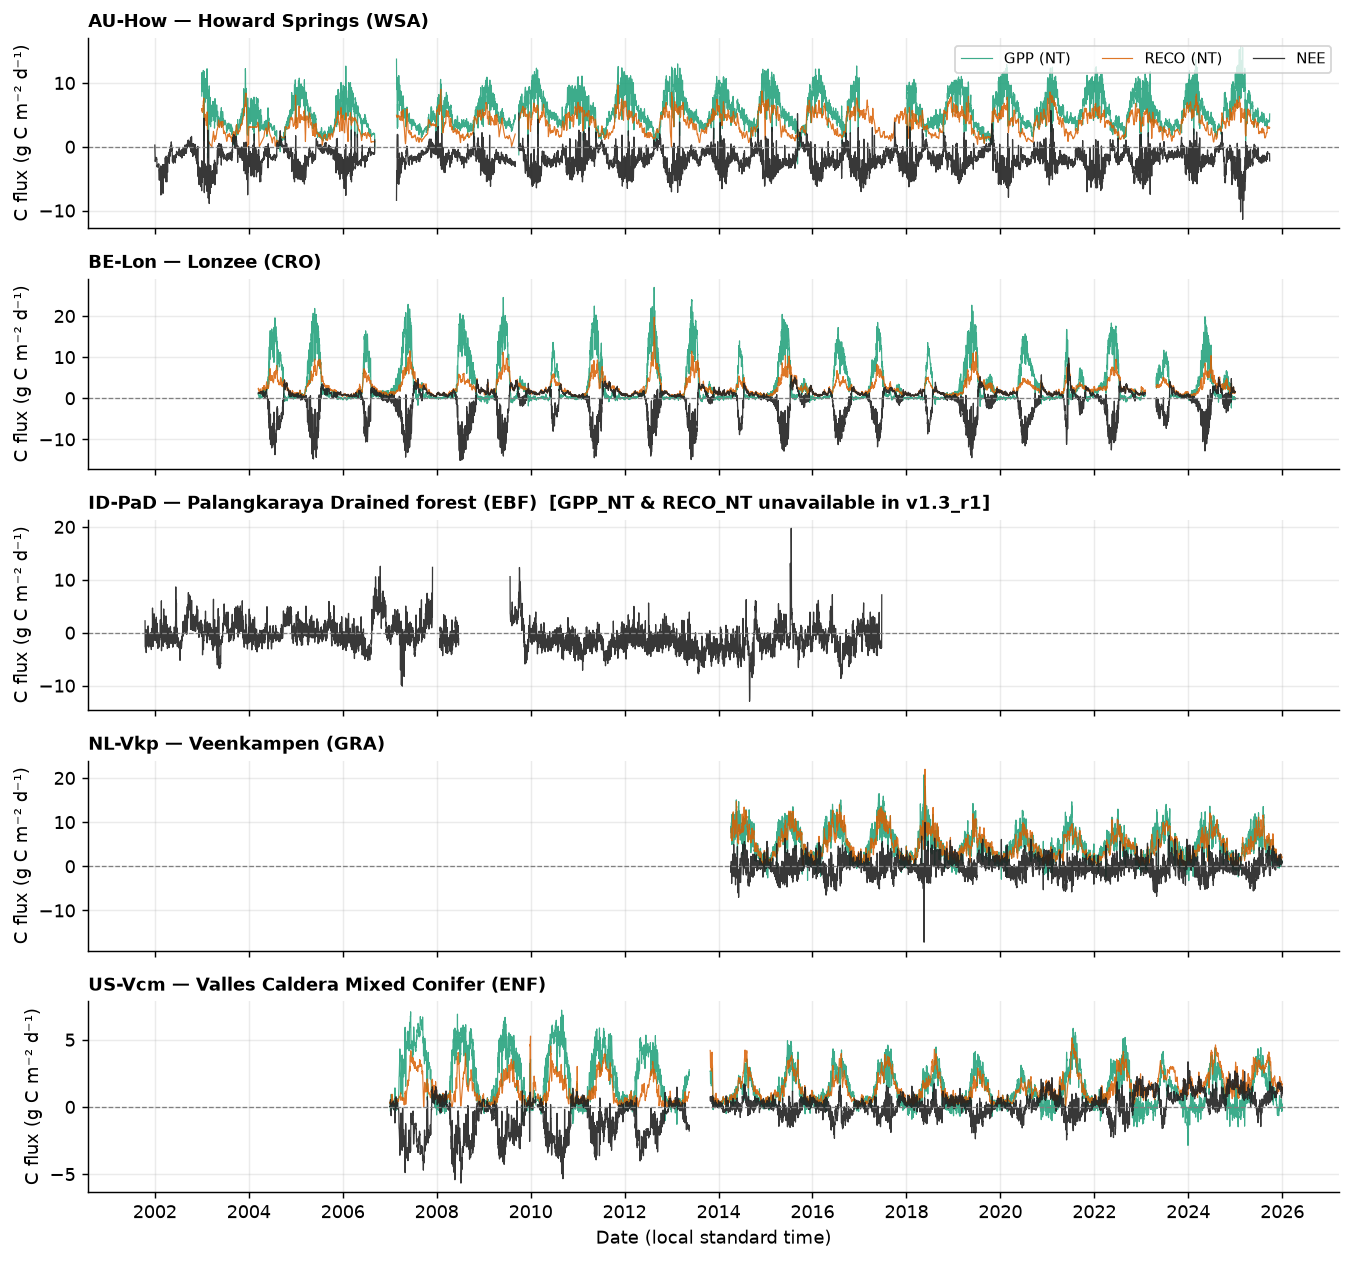

In [5]:
#| echo: false
#| warning: false
#| out-width: 100%
FACTOR = 1.0378  # 1 umol CO2 m-2 s-1 = 1.0378 g C m-2 d-1
df["date"] = df["time"].dt.floor("D")
daily = (
    df.groupby(["site", "date"])[["NEE_VUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF"]]
    .mean()
    * FACTOR
).reset_index()
# Check aggregation against official FLUXMET_DD file for US-Vcm
zp_vcm = Path("data/raw/AMF_US-Vcm_FLUXNET_2007-2025_v1.3_r1.zip")
with zipfile.ZipFile(zp_vcm) as z:
    dd_name = [n for n in z.namelist() if "FLUXMET_DD" in n][0]
    with z.open(dd_name) as f:
        dd_ref = pd.read_csv(f, na_values=[-9999, "-9999"], usecols=["TIMESTAMP", "NEE_VUT_REF"], dtype={"TIMESTAMP": str})
dd_ref["date"] = pd.to_datetime(dd_ref["TIMESTAMP"], format="%Y%m%d")
vcm_calc = daily[daily["site"] == "US-Vcm"].set_index("date")[["NEE_VUT_REF"]].rename(columns={"NEE_VUT_REF": "Aggregated HH (g C m⁻² d⁻¹)"})
check_dd = dd_ref.set_index("date")[["NEE_VUT_REF"]].rename(columns={"NEE_VUT_REF": "FLUXMET_DD (g C m⁻² d⁻¹)"}).join(vcm_calc)
check_dd["Abs diff"] = (check_dd["FLUXMET_DD (g C m⁻² d⁻¹)"] - check_dd["Aggregated HH (g C m⁻² d⁻¹)"]).abs()
print(f"US-Vcm FLUXMET_DD validation -> median abs diff: {check_dd['Abs diff'].median():.4f} g C m⁻² d⁻¹ (99th pct: {check_dd['Abs diff'].quantile(0.99):.4f})")
check_dd.to_csv(TAB_DIR / "c4_us_vcm_fluxmet_dd_validation.csv", encoding="utf-8-sig")
display(check_dd.head(4))
fig, axes = plt.subplots(len(SITES), 1, figsize=(10.5, 9.8), sharex=True)
for ax, site in zip(axes, SITES):
    sub = daily[daily["site"] == site].sort_values("date")
    ax.plot(sub["date"], sub["GPP_NT_VUT_REF"], color="#1b9e77", lw=0.65, alpha=0.85, label="GPP (NT)")
    ax.plot(sub["date"], sub["RECO_NT_VUT_REF"], color="#d95f02", lw=0.65, alpha=0.85, label="RECO (NT)")
    ax.plot(sub["date"], sub["NEE_VUT_REF"], color="#222222", lw=0.7, alpha=0.9, label="NEE")
    ax.axhline(0, color="gray", ls="--", lw=0.7)
    ax.set_ylabel("C flux (g C m⁻² d⁻¹)")
    sname = meta.loc[meta["site_id"] == site, "site_name"].iloc[0]
    igbp = meta.loc[meta["site_id"] == site, "igbp"].iloc[0]
    title_txt = f"{site} — {sname} ({igbp})"
    if sub["GPP_NT_VUT_REF"].isna().all():
        title_txt += "  [GPP_NT & RECO_NT unavailable in v1.3_r1]"
    ax.set_title(title_txt, loc="left", fontsize=10, fontweight="bold")
    if site == SITES[0]:
        ax.legend(loc="upper right", ncol=3, frameon=True, fontsize=8.5)
axes[-1].set_xlabel("Date (local standard time)")
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
fig.savefig(FIG_DIR / "c4_daily_carbon_flux_timeseries.png", dpi=200, bbox_inches="tight")
plt.show()

## C5. Seasonal Diurnal Cycles (Hemisphere-Aware)

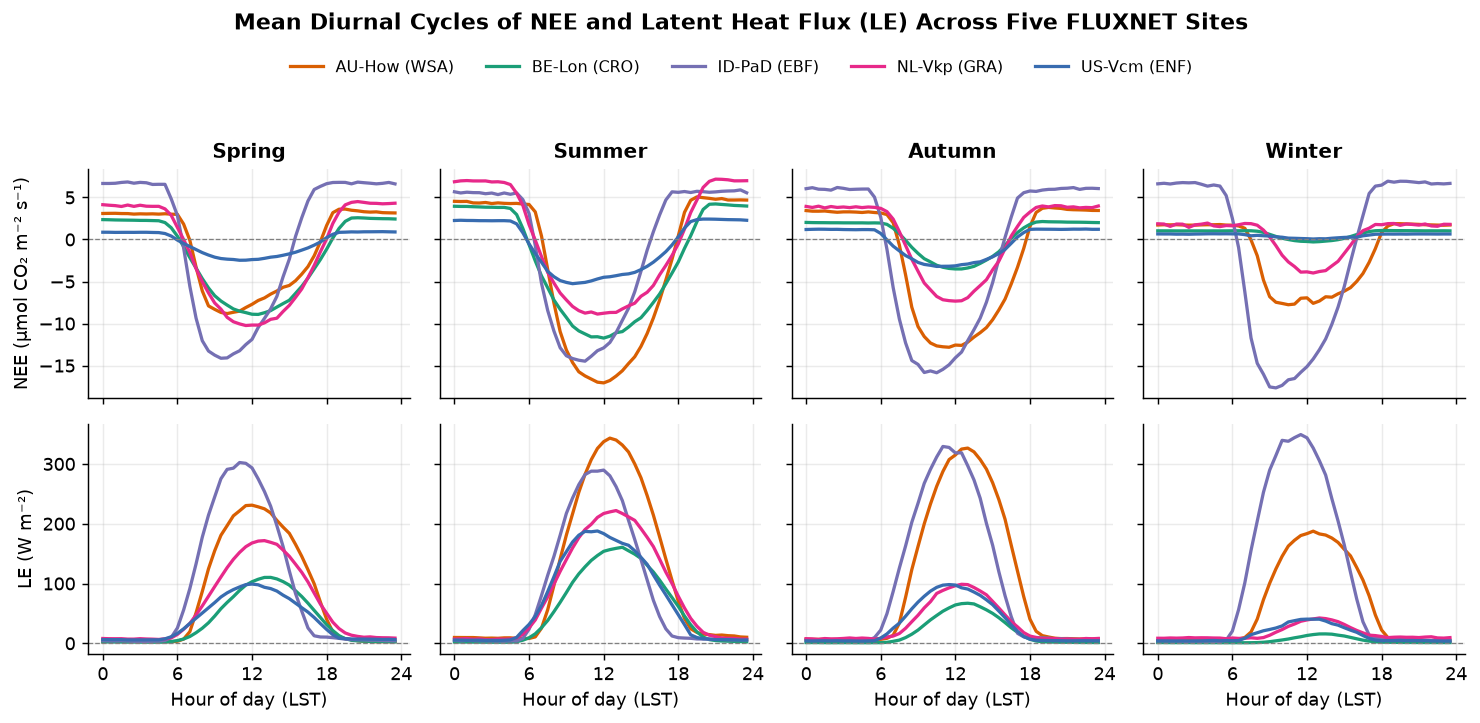

In [6]:
#| echo: false
#| warning: false
#| out-width: 100%
lat_map = dict(zip(meta["site_id"], meta["location_lat"]))
nh_season = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
sh_season = {
    12: "Summer", 1: "Summer", 2: "Summer",
    3: "Autumn", 4: "Autumn", 5: "Autumn",
    6: "Winter", 7: "Winter", 8: "Winter",
    9: "Spring", 10: "Spring", 11: "Spring",
}
is_nh = df["site"].map(lat_map) >= 0
df["season"] = np.where(is_nh, df["month"].map(nh_season), df["month"].map(sh_season))
season_order = ["Spring", "Summer", "Autumn", "Winter"]
diurnal = (
    df.groupby(["site", "season", "hour"])[["NEE_VUT_REF", "LE_F_MDS"]]
    .mean()
    .reset_index()
)
fig, axes = plt.subplots(2, 4, figsize=(11.5, 5.6), sharex=True, sharey="row")
for j, season in enumerate(season_order):
    ax_nee = axes[0, j]
    ax_le = axes[1, j]
    for site in SITES:
        sub = diurnal[(diurnal["site"] == site) & (diurnal["season"] == season)].sort_values("hour")
        igbp = meta.loc[meta["site_id"] == site, "igbp"].iloc[0]
        lbl = f"{site} ({igbp})"
        ax_nee.plot(sub["hour"], sub["NEE_VUT_REF"], color=SITE_COLORS[site], lw=1.8, label=lbl)
        ax_le.plot(sub["hour"], sub["LE_F_MDS"], color=SITE_COLORS[site], lw=1.8, label=lbl)
    ax_nee.axhline(0, color="gray", ls="--", lw=0.7)
    ax_le.axhline(0, color="gray", ls="--", lw=0.7)
    ax_nee.set_title(season, fontsize=11, fontweight="bold")
    ax_le.set_xlabel("Hour of day (LST)")
    ax_le.set_xticks([0, 6, 12, 18, 24])
axes[0, 0].set_ylabel("NEE (µmol CO₂ m⁻² s⁻¹)")
axes[1, 0].set_ylabel("LE (W m⁻²)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Mean Diurnal Cycles of NEE and Latent Heat Flux (LE) Across Five FLUXNET Sites", y=0.985, fontsize=12, fontweight="bold")
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.89])
fig.savefig(FIG_DIR / "c5_seasonal_diurnal_cycles.png", dpi=200, bbox_inches="tight")
plt.show()

## C6. Your Reading

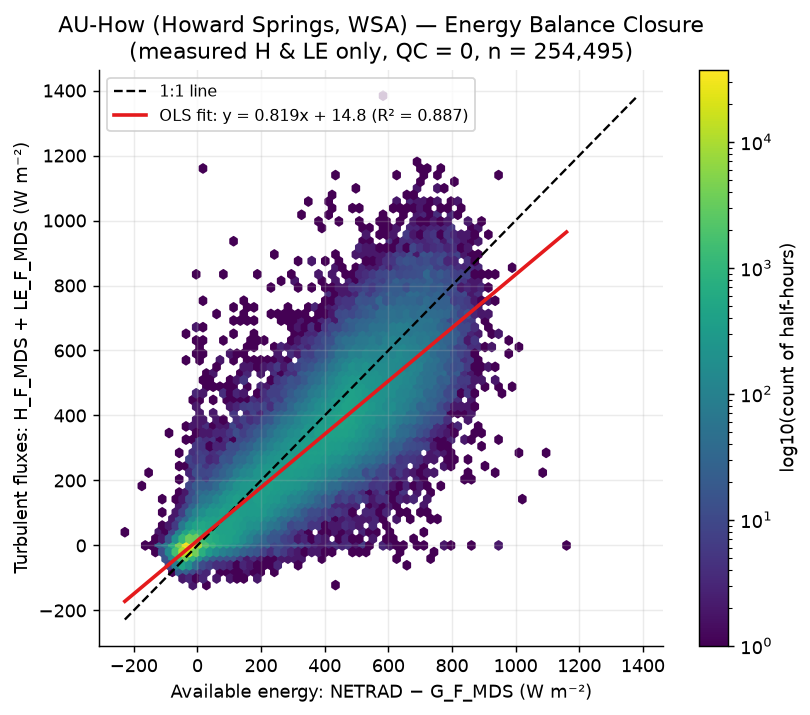

In [7]:
#| echo: false
#| warning: false
eb_site = "AU-How"
eb = df[df["site"] == eb_site]
ok = (eb["H_F_MDS_QC"] == 0) & (eb["LE_F_MDS_QC"] == 0) & eb["NETRAD"].notna() & eb["G_F_MDS"].notna()
eb = eb.loc[ok]
x = (eb["NETRAD"] - eb["G_F_MDS"]).to_numpy()
y = (eb["H_F_MDS"] + eb["LE_F_MDS"]).to_numpy()
slope, intercept = np.polyfit(x, y, 1)
r2 = np.corrcoef(x, y)[0, 1] ** 2
fig, ax = plt.subplots(figsize=(6.4, 5.6))
hb = ax.hexbin(x, y, gridsize=65, mincnt=1, cmap="viridis", bins="log")
fig.colorbar(hb, ax=ax, label="log10(count of half-hours)")
lims = [min(x.min(), y.min()), max(x.max(), y.max())]
x_line = np.linspace(x.min(), x.max(), 200)
ax.plot(lims, lims, "k--", lw=1.3, label="1:1 line")
ax.plot(x_line, slope * x_line + intercept, color="#e41a1c", lw=2.0,
        label=f"OLS fit: y = {slope:.3f}x + {intercept:.1f} (R² = {r2:.3f})")
ax.set_xlabel("Available energy: NETRAD − G_F_MDS (W m⁻²)")
ax.set_ylabel("Turbulent fluxes: H_F_MDS + LE_F_MDS (W m⁻²)")
ax.set_title(f"{eb_site} (Howard Springs, WSA) — Energy Balance Closure\n(measured H & LE only, QC = 0, n = {len(eb):,})")
ax.legend(loc="upper left", frameon=True, fontsize=9)
plt.tight_layout()
fig.savefig(FIG_DIR / "c6_au_how_energy_balance_closure.png", dpi=200, bbox_inches="tight")
plt.show()

### Synthesis & Comparison
Across the five towers, the tropical woody savanna **AU-How** takes up the most carbon per year (`−730.1 g C m⁻² yr⁻¹`), followed by the Belgian cropland **BE-Lon** (`−347.1 g C m⁻² yr⁻¹`), the Indonesian peatland forest **ID-PaD** (`−236.8 g C m⁻² yr⁻¹`), the subalpine conifer forest **US-Vcm** (`−96.9 g C m⁻² yr⁻¹`), and the Dutch grassland **NL-Vkp** (`−47.3 g C m⁻² yr⁻¹`). **BE-Lon** exhibits the largest seasonal cycle in monthly mean NEE (`6.24 µmol CO₂ m⁻² s⁻¹` amplitude between summer crop uptake and winter respiration), whereas **US-Vcm** has the smallest seasonal amplitude (`1.62 µmol CO₂ m⁻² s⁻¹`) and lowest productivity (`GPP = 587.3 g C m⁻² yr⁻¹`) at ~3,000 m elevation. Several patterns were surprising: **NL-Vkp** is nearly carbon-neutral despite high photosynthesis (`GPP = 1,820.5` vs `RECO = 1,784.3 g C m⁻² yr⁻¹`), **ID-PaD** lacks all night-time partitioned `GPP_NT_VUT_REF` and `RECO_NT_VUT_REF` values (`100%` `-9999` in `v1.3_r1`, though `_DT_` values exist), and **AU-How** shows remarkably strong net NEE uptake (noting that periodic savanna fire losses are not captured by eddy covariance). At **AU-How**, half-hourly energy balance closure against `NETRAD − G` yields a linear slope of `0.819` (`R² = 0.887`, `n = 254,495`), reflecting the typical ~18% energy imbalance of eddy covariance measurements. Finally, a large share of every record relies on gap-filling (`NEE_VUT_REF_QC > 0`): `55.1%` at **AU-How**, `56.2%` at **NL-Vkp**, `56.5%` at **BE-Lon**, `65.5%` (plus `15.1%` missing) at **ID-PaD**, and `74.9%` (`22.6%` measured) at **US-Vcm**.
## Data and Citation

In [8]:
#| echo: false
#| warning: false
lines = [
    f"### Site Data Citations (snapshot `{snap_path.name}`, version `v1.3_r1`)\n"
]
for _, r in meta.iterrows():
    lines.append(f"- **{r['site_id']} ({r['site_name']})**: {r['product_citation']}")
lines.extend([
    "",
    "### Methodological & Network References",
    "- Pastorello, G., Trotta, C., Canfora, E., et al. (2020). The FLUXNET2015 dataset and the ONEFlux processing pipeline for eddy covariance data. *Scientific Data*, 7, 225. <https://doi.org/10.1038/s41597-020-0534-3>",
    "- Ueyama, M., et al. (2025). JapanFlux2024: eddy covariance dataset (JPF). <https://doi.org/10.5194/essd-17-3807-2025>",
    "- Beringer, J., et al. (2016). An introduction to the Australian and New Zealand flux tower network – OzFlux. *Biogeosciences*, 13, 5895–5916. <https://doi.org/10.5194/bg-13-5895-2016>",
    "- Isaac, P., et al. (2017). OzFlux data: network integration from collection to curation. *Biogeosciences*, 14, 2903–2928. <https://doi.org/10.5194/bg-14-2903-2017>",
    "",
    "### FLUXNET Acknowledgement",
    "FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service. Funding for the AmeriFlux data service was provided by the U.S. Department of Energy Office of Science. TERN data are from the TERN Data Discovery Portal (<https://portal.tern.org.au/browse/theme>). All datasets are used under the CC-BY-4.0 license (<https://creativecommons.org/licenses/by/4.0/>) and were downloaded via the FLUXNET Shuttle (`fluxnet-shuttle`, snapshot `fluxnet_shuttle_snapshot_20261116T075027.csv`) on 16 November 2026.",
])
display(Markdown("\n".join(lines)))

### Site Data Citations (snapshot `fluxnet_shuttle_snapshot_20261116T075027.csv`, version `v1.3_r1`)

- **AU-How (Howard Springs)**: Beringer, J., Hutley, L., Northwood, M. (2026): Howard Springs FLUXNET Release 2026_r1 . Version 2026_r1. Terrestrial Ecosystem Research Network (TERN). (Dataset).
- **BE-Lon (Lonzee)**: Dumont, B., Heinesch, B., Bodson, B., Bogaerts, G., Chopin, H., De Ligne, A., Demoulin, L., Douxfils, B., Engelmann, T., Faurès, A., Longdoz, B., Manise, T., Orgun, A., Piret, A., Thyrion, T. (2026). Fluxnet Archive Product from Lonzee, 2004–2024, FLUXNET, https://hdl.handle.net/11676/1u2xQ5XcQoX0j2wJiZcyDP3M
- **ID-PaD (Palangkaraya Drained forest)**: Hirano, T., Ohkubo, S. (2026). Fluxnet Archive Product from Palangkaraya Drained forest, 2001–2017, FLUXNET, https://hdl.handle.net/11676/RaxQP0fkOSWCXKIIhi7Bnevj
- **NL-Vkp (Veenkampen)**: Barten, J., Hartogensis, O., Heusinkveld, B. (2026). Fluxnet Archive Product from Veenkampen, 2014–2025, FLUXNET, https://hdl.handle.net/11676/NjPFe8mMhEmbG6xHDtKSw-sx
- **US-Vcm (Valles Caldera Mixed Conifer)**: Marcy Litvak (2026), AmeriFlux FLUXNET-1F US-Vcm Valles Caldera Mixed Conifer, Ver. v1.3_r1 (2007-2025), AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/2229391

### Methodological & Network References
- Pastorello, G., Trotta, C., Canfora, E., et al. (2020). The FLUXNET2015 dataset and the ONEFlux processing pipeline for eddy covariance data. *Scientific Data*, 7, 225. <https://doi.org/10.1038/s41597-020-0534-3>
- Ueyama, M., et al. (2025). JapanFlux2024: eddy covariance dataset (JPF). <https://doi.org/10.5194/essd-17-3807-2025>
- Beringer, J., et al. (2016). An introduction to the Australian and New Zealand flux tower network – OzFlux. *Biogeosciences*, 13, 5895–5916. <https://doi.org/10.5194/bg-13-5895-2016>
- Isaac, P., et al. (2017). OzFlux data: network integration from collection to curation. *Biogeosciences*, 14, 2903–2928. <https://doi.org/10.5194/bg-14-2903-2017>

### FLUXNET Acknowledgement
FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service. Funding for the AmeriFlux data service was provided by the U.S. Department of Energy Office of Science. TERN data are from the TERN Data Discovery Portal (<https://portal.tern.org.au/browse/theme>). All datasets are used under the CC-BY-4.0 license (<https://creativecommons.org/licenses/by/4.0/>) and were downloaded via the FLUXNET Shuttle (`fluxnet-shuttle`, snapshot `fluxnet_shuttle_snapshot_20261116T075027.csv`) on 16 November 2026.